In [1]:
import os
import pandas as pd
import yaml
import numpy as np
import matplotlib.pyplot as plt
from search_results import load_trial_results, generate_summary_table, get_kfold_mean_metrics, plot_learning_curves
import torch
import random
from pytorch_lightning import seed_everything
from dataset.tracking_dataset import load_data_list
from sklearn.model_selection import train_test_split
from train.train_lstm import train_lstm_pipeline

#### Descargar logs

In [3]:
# !lightning download folder logs/bayesian_log/trial_8 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_8
# !lightning download folder logs/bayesian_log/trial_9 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_9
# !lightning download folder logs/bayesian_log/trial_10 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_10
# !lightning download folder logs/bayesian_log/trial_11 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_11
# !lightning download folder logs/bayesian_log/trial_12 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_12
# !lightning download folder logs/bayesian_log/trial_13 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_13
# !lightning download folder logs/bayesian_log/trial_14 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_14
# !lightning download folder logs/bayesian_log/trial_15 --studio mmia-2da-cohorte/speedestimation --local_path /home/vsalcedop/PROYECTO_FINAL/logs/bayesian_log/trial_15

## Optimización de Hiperparámetros

### Resultados de Bayesian Search loss - std

In [4]:
log_directory = '../../logs/bayesian_log'

trials = 16
folds = 5

df_results = load_trial_results(
    base_log_dir=log_directory,
    n_trials=trials,
    n_folds=folds
)

summary_table = generate_summary_table(df_results)
print("Tabla de Resumen Estadístico por Trial:")
display(summary_table)

/usr/local/lib/python3.10/dist-packages/torch/nn/modules/rnn.py:83: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.007203406243608278 and num_layers=1
  warnings.warn("dropout option adds dropout after all but last "
/usr/local/lib/python3.10/dist-packages/torch/nn/modules/rnn.py:83: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.0031806158701979223 and num_layers=1
  warnings.warn("dropout option adds dropout after all but last "
/usr/local/lib/python3.10/dist-packages/torch/nn/modules/rnn.py:83: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.17907345777926564 and num_layers=1
  warnings.warn("dropout option adds dropout after all but last "
/usr/local/lib/python3.10/dist-packages/

Mejor combinación de hiperparámetros (Trial 15.0) basada en val_loss mínimo.
Tabla de Resumen Estadístico por Trial:


,Trial,Hidden Size,Num Layers,Dropout,Lr,Weight Decay,Trainable Params,MSE (Val),MAE (Val),RelAcc (Val),Folds,Mejor Trial
0,15.0,128,3,0.06,4.4e-04,3.5e-05,"344,193.0",10.869 ± 2.027,1.528 ± 0.181,0.980 ± 0.002,5.0,<-- MEJOR
1,14.0,128,3,0.09,5.3e-04,3.6e-05,"344,193.0",11.475 ± 1.243,1.532 ± 0.112,0.980 ± 0.002,5.0,
2,13.0,64,3,0.08,5.1e-04,3.5e-05,"90,177.0",11.552 ± 1.385,1.606 ± 0.085,0.979 ± 0.001,5.0,
3,12.0,64,3,0.10,5.5e-04,4.3e-05,"90,177.0",12.502 ± 1.215,1.651 ± 0.084,0.979 ± 0.001,5.0,
4,1.0,64,1,0.01,1.6e-04,4.0e-06,"23,617.0",12.622 ± 1.116,1.883 ± 0.060,0.976 ± 0.001,5.0,
5,3.0,64,3,0.21,1.3e-03,7.4e-05,"90,177.0",12.767 ± 1.836,1.980 ± 0.269,0.975 ± 0.003,5.0,
6,5.0,32,2,0.16,1.2e-03,3.3e-06,"16,161.0",13.339 ± 1.363,1.970 ± 0.206,0.975 ± 0.002,5.0,
7,11.0,64,3,0.27,1.7e-03,6.6e-06,"90,177.0",13.349 ± 1.198,1.987 ± 0.113,0.975 ± 0.002,5.0,
8,9.0,64,1,0.28,7.8e-04,5.7e-06,"23,617.0",13.367 ± 1.007,2.008 ± 0.189,0.974 ± 0.002,5.0,
9,2.0,32,3,0.08,3.5e-04,8.1e-05,"24,609.0",14.140 ± 1.406,1.951 ± 0.146,0.975 ± 0.002,5.0,


In [5]:
def plot_learning_curves(epoch_summary, title='Curva de Aprendizaje', save_path=None):
    plt.figure(figsize=(8, 5))
    plot_legend = False

    if 'mean_train_loss' in epoch_summary.columns and epoch_summary['mean_train_loss'].notna().any():
        plt.plot(epoch_summary['epoch'], epoch_summary['mean_train_loss'], label='Train Loss (promedio)')
        plt.fill_between(epoch_summary['epoch'],
                            epoch_summary['mean_train_loss'] - epoch_summary['std_train_loss'],
                            epoch_summary['mean_train_loss'] + epoch_summary['std_train_loss'],
                            alpha=0.2, label='Train Loss (±σ)')
        plot_legend = True

    if 'mean_val_loss' in epoch_summary.columns and epoch_summary['mean_val_loss'].notna().any():
        plt.plot(epoch_summary['epoch'], epoch_summary['mean_val_loss'], label='Validation Loss (promedio)')
        plt.fill_between(epoch_summary['epoch'],
                            epoch_summary['mean_val_loss'] - epoch_summary['std_val_loss'],
                            epoch_summary['mean_val_loss'] + epoch_summary['std_val_loss'],
                            alpha=0.2, label='Validation Loss (±σ)')
        plot_legend = True

    plt.title(title)
    plt.xlabel('Época')
    plt.ylabel('MSE')
    plt.yscale('log')
    if plot_legend:
        plt.legend()
    plt.grid(True)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, format='svg', bbox_inches='tight')
        print(f"Gráfica guardada en: {save_path}")

    plt.show()

In [6]:
best_params = df_results.iloc[0].to_dict()

Gráfica guardada en: ims/learning_curve_best_model.svg


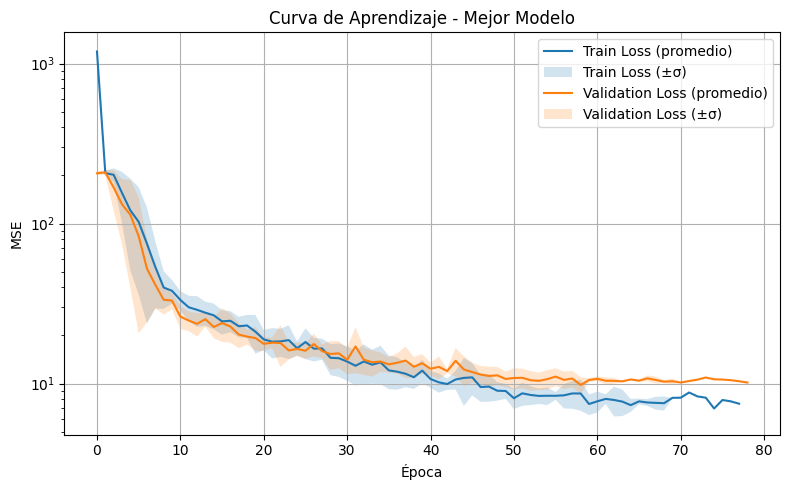

In [7]:
# Graficar curvas de aprendizaje
mean_metrics = get_kfold_mean_metrics(log_directory, best_params, folds)
plot_learning_curves(mean_metrics, 
                    title='Curva de Aprendizaje - Mejor Modelo',
                    save_path='ims/learning_curve_best_model.svg')


### Reentrenar modelo con mejores hiperparámetros

In [8]:
ALL_VIDEOS = [
    ('session1', 'center'),
    ('session1', 'left'),
    ('session1', 'right'),
    ('session2', 'center'),
    ('session2', 'left'),
    ('session2', 'right'),
    ('session3', 'center'),
    ('session3', 'left'),
    ('session3', 'right'),
    ('session4', 'center'),
    ('session4', 'left'),
    ('session4', 'right'),
    ('session5', 'center'),
    ('session5', 'left'),
    ('session5', 'right'),
    ('session6', 'center'),
    ('session6', 'left'),
    ('session6', 'right'),
]

In [9]:
seed = 47
seed_everything(seed)
random.seed(seed)
np.random.seed(seed)

full_list = load_data_list(ALL_VIDEOS, results_folder='../../results_instance', feature_path='all_features')
all_idx = np.arange(len(full_list))
train_val_idx, test_idx = train_test_split(
    all_idx, test_size=0.2, random_state=seed, shuffle=True
)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.2, random_state=seed, shuffle=True
)
train_list = [full_list[i] for i in train_idx]
val_list = [full_list[i] for i in val_idx]
test_list = [full_list[i] for i in test_idx]

INFO:lightning_fabric.utilities.seed:Seed set to 47


In [ ]:
hparams = best_params
input_size = len(train_list[0]['features'][0])

data_module, model, trainer, logger, result = train_lstm_pipeline(
    # Dataset
    data_list=full_list,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,

    # DataModule params
    batch_size=4,
    split_ratio=(0.64, 0.16, 0.2),
    num_workers=4,

    # LSTM params
    input_size=input_size,
    hidden_size=int(hparams['hidden_size']),
    num_layers=int(hparams['num_layers']),
    output_size=1,
    learning_rate=hparams['lr'],
    dropout=hparams['dropout'],
    weight_decay=hparams['weight_decay'],

    # Logger
    log_path='best_model',

    # Trainer
    patience=7,
    epochs=100,
    log_every_n_steps=10,
)

In [ ]:
trainer.test(model, datamodule=data_module)

In [ ]:
predictions = trainer.predict(model, dataloaders=data_module.test_dataloader())
pred_df = pd.DataFrame(predictions, columns=["pred", "target"])

In [ ]:
df_pred = pd.DataFrame(
    [
        (
            pred[i].item(),
            real[i].item(),
            abs(pred[i].item() - real[i].item())
        )
        for (pred, real) in predictions
        for i in range(len(pred))
    ],
    columns=["Velocidad Predicha", "Velocidad Real", "Error km/h"]
)
df_pred.head(10)